# Predicción del precio de coches usados

**Proyecto del curso:** evaluación y selección de modelos supervisados, aplicado a un dataset real
descargado de Kaggle.

Este proyecto sigue la estructura de la sesión 7 (*Evaluating and Selecting Supervised Models*),
pero con dos diferencias importantes. Los datos no vienen limpios: hay que pasar por un **análisis
exploratorio (EDA)** y una **limpieza** antes de modelar. Y todo el preprocesamiento va dentro de un
**pipeline** de `scikit-learn`, para que nada de los datos de validación o de prueba se filtre al
entrenamiento.

## Objetivos

1. Explorar un dataset real y detectar sus problemas de calidad: tipos incorrectos, nulos ocultos,
   texto que contiene varios datos y valores atípicos.
2. Limpiarlo y extraer variables útiles (*feature engineering*), justificando cada decisión.
3. Construir un pipeline completo (imputación, escalado, codificación y transformación del objetivo).
4. Organizar un **torneo de seis modelos** con validación cruzada, leyendo cada resultado como un
   rango y no como un punto.
5. Diagnosticar **sesgo y varianza** a partir de los errores de entrenamiento y de validación.
6. Ajustar los hiperparámetros de los finalistas, **justificar por qué gana el campeón** y
   evaluarlo **una sola vez** en el conjunto de prueba.

## Índice

1. El problema y los datos
2. Carga de datos
3. EDA inicial: los datos tal como llegan
4. Limpieza y *feature engineering*
5. EDA sobre los datos limpios
6. División entrenamiento / prueba
7. El pipeline de preprocesamiento
8. El torneo: reglas y competidores
9. Ronda 1: fase de grupos
10. Sesgo y varianza
11. Una decisión de pipeline: transformar el objetivo
12. Ronda 2: la final
13. ¿Por qué gana el campeón?
14. Evaluación final en el conjunto de prueba
15. ¿Qué ha aprendido el modelo?
16. Conclusiones

## 1. El problema y los datos

**Pregunta:** dado el anuncio de un coche usado (marca, año, kilometraje, motor, etc.), ¿qué precio
de venta cabe esperar?

Es un problema de **regresión**, como el de Auto MPG en la sesión 7, pero con datos mucho más
desordenados.

**Dataset:** [Used Car Price Prediction Dataset](https://www.kaggle.com/datasets/taeefnajib/used-car-price-prediction-dataset)
(Kaggle, autor *taeefnajib*), con 4.009 anuncios extraídos de cars.com.

| Columna | Contenido original |
|---|---|
| `brand`, `model` | marca y modelo |
| `model_year` | año del modelo |
| `milage` | kilometraje, como texto: `"51,000 mi."` |
| `fuel_type` | tipo de combustible |
| `engine` | descripción libre del motor: `"300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability"` |
| `transmission` | descripción libre de la transmisión: `"6-Speed A/T"`, `"Manual, 6-Spd"`… |
| `ext_col`, `int_col` | color exterior e interior, con nombres comerciales (`"Glacier White Metallic"`) |
| `accident` | si se ha reportado algún accidente |
| `clean_title` | si el título de propiedad está limpio |
| `price` | **objetivo**, como texto: `"$10,300"` |

**Por qué este dataset:**

- Tiene el tamaño adecuado: unos 4.000 coches, suficientes para que la validación cruzada sea
  estable y lo bastante pocos para que todo se ejecute en segundos.
- Obliga a limpiar de verdad. Casi ninguna columna se puede usar tal cual: hay que extraer números
  de texto, reconocer nulos disfrazados, unificar categorías y decidir qué hacer con los atípicos.
- Es el mismo dominio que la plantilla (coches), así que las intuiciones de la sesión 7 se pueden
  trasladar.

La celda siguiente importa todo lo necesario y fija la semilla para que los resultados sean
reproducibles.

In [1]:
from pathlib import Path
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    cross_validate,
    train_test_split,
    validation_curve,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
dollars = FuncFormatter(lambda v, _: f"${v:,.0f}")

## 2. Carga de datos

El CSV se guarda en `data/used_cars.csv`. Si no existe, la celda lo descarga de Kaggle con
`kagglehub`, que para datasets públicos no necesita cuenta. Para instalarlo:
`pip install kagglehub`.

> **Nota:** en redes con inspección SSL (antivirus o proxy corporativo), la descarga puede fallar
> con `CERTIFICATE_VERIFY_FAILED`. Se soluciona instalando `truststore`, que hace que Python use
> los certificados del sistema operativo. Otra opción es descargar el CSV a mano desde la página de
> Kaggle y guardarlo en `data/`.

In [2]:
DATA_PATH = Path("data/used_cars.csv")

if not DATA_PATH.exists():
    import shutil

    import kagglehub

    try:
        import truststore

        truststore.inject_into_ssl()
    except ImportError:
        pass
    downloaded = kagglehub.dataset_download("taeefnajib/used-car-price-prediction-dataset")
    DATA_PATH.parent.mkdir(exist_ok=True)
    shutil.copy(Path(downloaded) / "used_cars.csv", DATA_PATH)

raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]} filas x {raw.shape[1]} columnas")

4009 filas x 12 columnas


## 3. EDA inicial: los datos tal como llegan

Antes de cambiar nada, conviene mirar los datos con desconfianza. La celda siguiente muestra las
primeras filas.

In [3]:
raw.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


La tabla siguiente resume cada columna: tipo, nulos, número de valores distintos y un ejemplo.
Es la vista más útil para planificar la limpieza.

In [4]:
pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "nulos": raw.isna().sum(),
    "% nulos": (raw.isna().mean() * 100).round(1),
    "valores distintos": raw.nunique(),
    "ejemplo": raw.iloc[0],
})

,tipo,nulos,% nulos,valores distintos,ejemplo
brand,str,0,0.0,57,Ford
model,str,0,0.0,1898,Utility Police Interceptor Base
model_year,int64,0,0.0,34,2013
milage,str,0,0.0,2818,"51,000 mi."
fuel_type,str,170,4.2,7,E85 Flex Fuel
engine,str,0,0.0,1146,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...
transmission,str,0,0.0,62,6-Speed A/T
ext_col,str,0,0.0,319,Black
int_col,str,0,0.0,156,Black
accident,str,113,2.8,2,At least 1 accident or damage reported


Esta tabla ya muestra los principales problemas:

- **Solo `model_year` es numérica.** `price` y `milage` deberían ser números, pero se leen como
  texto por los símbolos `$`, `,` y `mi.`.
- **`clean_title` tiene un único valor** (`"Yes"`) y un 14,9 % de nulos. En realidad es una
  variable binaria: "consta un título limpio" frente a "no consta".
- **Cardinalidad desmesurada.** `model` tiene 1.898 valores distintos en 4.009 filas, `engine` tiene
  1.146 y `ext_col` tiene 319. Así no se pueden codificar con one-hot directamente.
- Los nulos visibles son pocos: un 4,2 % en `fuel_type` y un 2,8 % en `accident`. Pero esto es solo
  lo que detecta `isna()`.

### Nulos disfrazados

`isna()` solo detecta los `NaN` reales. Los datos extraídos de webs suelen marcar la ausencia de
información con un guion u otro texto. La celda siguiente cuenta esos valores en cada columna.

In [5]:
HIDDEN_NA = ["–", "-", "not supported", ""]

raw.isin(HIDDEN_NA).sum().loc[lambda s: s > 0].rename("nulos disfrazados")

fuel_type        47
engine           45
transmission      4
ext_col          15
int_col         133
Name: nulos disfrazados, dtype: int64

Hay bastantes más nulos de los que parecía. `int_col` tiene 133 guiones (un 3,3 %) que
`isna()` contaba como un color más. `engine` tiene 45 filas sin información. Y `fuel_type` suma 47
valores inválidos a sus 170 nulos, así que en total le falta el dato a 217 coches (un 5,4 %).

### Las columnas categóricas pequeñas

La celda siguiente muestra la frecuencia de cada valor en las columnas categóricas con pocas
categorías, incluidos los nulos.

In [6]:
for col in ["fuel_type", "accident", "clean_title"]:
    print(raw[col].value_counts(dropna=False).to_string(), end="\n\n")

fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2

accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113

clean_title
Yes    3413
NaN     596



- En `fuel_type` **no existe la categoría "Electric"**, aunque el dataset tiene Tesla, Rivian y
  Lucid. Se verá en 4.5 que los eléctricos son precisamente los que tienen el combustible vacío.
- `accident` está desequilibrada pero es útil: aproximadamente uno de cada cuatro coches tiene un
  accidente reportado.
- `clean_title` confirma lo visto antes: solo tiene `"Yes"` o vacío.

### Las columnas de texto libre

`engine` y `transmission` son texto libre con cientos de variantes. La celda siguiente muestra
una muestra aleatoria de cada una para ver qué patrones se repiten.

In [7]:
sample = raw.sample(12, random_state=1)
for engine, transmission in zip(sample["engine"], sample["transmission"]):
    print(f"{transmission:<35} | {engine}")

8-Speed A/T                         | 291.0HP 3.8L V6 Cylinder Engine Gasoline Fuel
A/T                                 | 315.0HP 4.6L 8 Cylinder Engine Gasoline Fuel
6-Speed Automatic                   | 6.2L V8 16V MPFI SOHC Flexible Fuel
10-Speed A/T                        | 409.0HP 3.4L V6 Cylinder Engine Gasoline Fuel
Automatic                           | 2.0 Liter Turbo
6-Speed M/T                         | 412.0HP 5.0L 8 Cylinder Engine Gasoline Fuel
A/T                                 | 295.0HP 3.5L V6 Cylinder Engine Gasoline Fuel
A/T                                 | 411.0HP 6.2L 8 Cylinder Engine Gasoline Fuel
7-Speed A/T                         | 241.0HP 2.0L 4 Cylinder Engine Gasoline Fuel
1-Speed A/T                         | 214.0HP Electric Motor Electric Fuel System
8-Speed A/T                         | 300.0HP 3.0L Straight 6 Cylinder Engine Gasoline Fuel
Transmission w/Dual Shift Mode      | 429.0HP 4.6L 8 Cylinder Engine Gasoline Fuel


Las dos columnas siguen unos pocos formatos que se repiten:

- `engine` aparece al menos en dos formatos. El largo (`"291.0HP 3.8L V6 Cylinder Engine…"`)
  incluye potencia, cilindrada y cilindros. El corto (`"6.2L V8 16V MPFI SOHC"`, `"2.0 Liter
  Turbo"`) no incluye la potencia. Por tanto, la potencia faltará en una parte de los coches.
- `transmission` mezcla abreviaturas (`A/T`, `M/T`), palabras completas (`Automatic`) y
  descripciones comerciales (`"Transmission w/Dual Shift Mode"`).

De ambas columnas se pueden extraer variables numéricas y categóricas limpias con expresiones
regulares.

### Duplicados

Por último, se comprueba si hay filas repetidas.

In [8]:
print(f"filas duplicadas: {raw.duplicated().sum()}")

filas duplicadas: 0


## 4. Limpieza y *feature engineering*

Cada paso de esta sección es una **regla fija que se aplica fila a fila**: no depende de
estadísticas calculadas sobre el conjunto de datos, como medias o frecuencias. Por eso se puede
aplicar antes de separar entrenamiento y prueba sin filtrar información.

Lo que sí aprende de los datos (las medianas para imputar, las medias y desviaciones para escalar,
las categorías frecuentes) se hace más adelante, **dentro del pipeline**, y solo con los datos de
entrenamiento de cada fold.

### 4.1 Precio y kilometraje a número

Se quitan `$`, comas y `mi.`, y se convierten a número. También se corrige la errata del nombre
de la columna: `milage` pasa a `mileage`.

In [9]:
cars = raw.copy()
cars["price"] = cars["price"].str.replace(r"[$,]", "", regex=True).astype(float)
cars["mileage"] = cars.pop("milage").str.replace(r"[^0-9]", "", regex=True).astype(float)

cars[["price", "mileage"]].describe().round(0)

,price,mileage
count,4009.0,4009.0
mean,44553.0,64718.0
std,78711.0,52297.0
min,2000.0,100.0
25%,17200.0,23044.0
50%,31000.0,52775.0
75%,49990.0,94100.0
max,2954083.0,405000.0


Las dos columnas ya son numéricas y aparecen los primeros indicios de valores extremos:

- **Precio:** la media (44.553 $) está muy por encima de la mediana (31.000 $). Es la señal de una
  cola larga hacia los precios altos. El máximo, de **2.954.083 $**, merece una revisión
  (sección 4.9).
- **Kilometraje:** de 100 a 405.000 millas, con mediana de 52.775. Son valores plausibles para coches
  usados.

### 4.2 Nulos disfrazados a `NaN`

Los guiones y `"not supported"` se convierten en nulos reales, para que el resto del código y el
imputador del pipeline los traten como lo que son.

In [10]:
cars = cars.replace(HIDDEN_NA, np.nan)
cars.isna().sum().loc[lambda s: s > 0].rename("nulos")

fuel_type       217
engine           45
transmission      4
ext_col          15
int_col         133
accident        113
clean_title     596
Name: nulos, dtype: int64

### 4.3 Marcas partidas

El scraper cortó por el primer espacio las marcas de dos palabras: "Land Rover" aparece como
`brand = "Land"` con `model = "Rover Range Rover…"`. La celda siguiente las repara.

In [11]:
BRAND_FIXES = {"Land": "Land Rover", "Alfa": "Alfa Romeo", "Aston": "Aston Martin"}
cars["brand"] = cars["brand"].replace(BRAND_FIXES)

cars["brand"].value_counts().head(10)

brand
Ford             386
BMW              375
Mercedes-Benz    315
Chevrolet        292
Porsche          201
Audi             200
Toyota           199
Lexus            163
Jeep             143
Land Rover       130
Name: count, dtype: int64

### 4.4 Extraer variables del motor

La columna `engine` contiene varios datos en una sola cadena. Con expresiones regulares se
extraen:

- `hp`: la potencia, si aparece (`"300.0HP"`).
- `engine_l`: la cilindrada en litros (`"3.7L"` o `"3.5 Liter"`).
- `cylinders`: el número de cilindros (`"V6"`, `"I4"`, `"4 Cylinder"`, `"Straight 6"`…).
- `turbo`: 1 si el motor es turbo o sobrealimentado.

Cuando el dato no aparece en el texto, queda como `NaN` y lo resolverá el imputador del pipeline.

In [12]:
engine = cars["engine"].fillna("")

cars["hp"] = engine.str.extract(r"(\d+(?:\.\d+)?)HP", expand=False).astype(float)
cars["engine_l"] = (
    engine.str.extract(r"(\d+(?:\.\d+)?)\s*(?:L\b|Liter)", expand=False).astype(float)
)
cars["cylinders"] = (
    engine.str.extract(r"\b[VIHW](\d{1,2})\b|(\d{1,2}) Cylinder|Straight (\d{1,2})")
    .bfill(axis=1)
    .iloc[:, 0]
    .astype(float)
)
cars["turbo"] = engine.str.contains(r"turbo|supercharg", case=False).astype(int)

cars[["hp", "engine_l", "cylinders", "turbo"]].describe().round(2)

,hp,engine_l,cylinders,turbo
count,3201.00,3792.00,3589.00,4009.00
mean,332.21,3.68,6.22,0.08
std,122.26,1.42,1.72,0.27
min,70.00,0.65,3.00,0.00
25%,248.00,2.50,4.00,0.00
50%,310.00,3.50,6.00,0.00
75%,400.00,4.70,8.00,0.00
max,1020.00,8.40,16.00,1.00


Los rangos extraídos son plausibles, lo que confirma que las expresiones regulares funcionan:

- `hp` va de 70 a 1.020 CV (el Tesla Model S Plaid anuncia 1.020) y se ha podido extraer en el 80 %
  de los coches. El resto usa el formato corto sin potencia.
- `engine_l` va de 0,65 L (el extensor de autonomía del BMW i3) a 8,4 L (Dodge Viper), con un 95 %
  de cobertura.
- `cylinders` va de 3 a 16 (el W16 del Bugatti Veyron).
- Un 8 % de los motores son turbo o sobrealimentados.

### 4.5 Recuperar el combustible de los eléctricos

En la sección 3, `fuel_type` no tenía ninguna categoría "Electric", pero sí 87 Tesla. La celda
siguiente mira qué marcas tienen el combustible vacío.

In [13]:
cars.loc[cars["fuel_type"].isna(), "brand"].value_counts().head(8)

brand
Tesla        87
Rivian       17
Ford         17
Porsche      11
Chevrolet     8
Nissan        8
Dodge         8
Toyota        6
Name: count, dtype: int64

Los coches eléctricos se publicaron sin combustible, pero su motor dice
`"Electric Motor Electric Fuel System"`. Se recupera la categoría a partir de ese texto, excluyendo
los híbridos (`"Gas/Electric"`).

Además, un eléctrico no tiene cilindros ni cilindrada. Para ellos esas variables valen **0**: es su
valor real, no un dato desconocido que haya que imputar.

In [14]:
is_electric = engine.str.contains("electric", case=False) & ~engine.str.contains(
    r"gas|hybrid", case=False
)
cars.loc[cars["fuel_type"].isna() & is_electric, "fuel_type"] = "Electric"
cars.loc[cars["fuel_type"].eq("Electric"), ["engine_l", "cylinders"]] = 0

print(cars["fuel_type"].value_counts(dropna=False).to_string())

fuel_type
Gasoline          3309
Hybrid             194
Electric           167
E85 Flex Fuel      139
Diesel             116
NaN                 50
Plug-In Hybrid      34


### 4.6 Simplificar la transmisión

Las 62 variantes de `transmission` se reducen a lo que importa:

- `transmission_type`: `Automatic`, `Manual` o `CVT`. El orden de las comprobaciones importa: una
  automática con modo manual (`"Automatic, 8-Spd Sport w/Sport & Manual Modes"`) sigue siendo
  automática.
- `gears`: el número de marchas, cuando aparece.

In [15]:
def transmission_type(text):
    if pd.isna(text):
        return np.nan
    t = text.lower()
    if "cvt" in t:
        return "CVT"
    if re.search(r"a/t|\bat\b|auto|dual shift|dct|pdk|single-speed|fixed gear", t):
        return "Automatic"
    if re.search(r"m/t|manual|\bmt\b", t):
        return "Manual"
    return np.nan


cars["transmission_type"] = cars["transmission"].map(transmission_type)
cars["gears"] = (
    cars["transmission"]
    .str.extract(r"(\d+)[\s-]*(?:speed|spd)", flags=re.IGNORECASE, expand=False)
    .astype(float)
)

print(cars["transmission_type"].value_counts(dropna=False).to_string())

transmission_type
Automatic    3513
Manual        373
CVT           100
NaN            23


### 4.7 Agrupar los colores

`ext_col` tiene más de 300 valores porque cada fabricante usa nombres comerciales:
`"Glacier White Metallic"`, `"Bright White Clearcoat"`… Se reducen a un color básico buscando
palabras clave. Lo que no encaja en ninguna va a `"Other"`.

In [16]:
BASIC_COLORS = {
    "black": "Black", "ebony": "Black", "onyx": "Black", "obsidian": "Black",
    "white": "White", "pearl": "White", "ivory": "White",
    "gray": "Gray", "grey": "Gray", "graphite": "Gray", "charcoal": "Gray", "granite": "Gray",
    "silver": "Silver", "platinum": "Silver",
    "blue": "Blue", "red": "Red", "green": "Green",
    "brown": "Brown", "beige": "Beige", "tan": "Beige", "camel": "Beige", "parchment": "Beige",
    "gold": "Gold", "orange": "Orange", "yellow": "Yellow", "purple": "Purple",
}


def basic_color(text):
    if pd.isna(text):
        return np.nan
    for keyword, color in BASIC_COLORS.items():
        if re.search(rf"\b{keyword}\b", text, flags=re.IGNORECASE):
            return color
    return "Other"


cars["ext_color"] = cars["ext_col"].map(basic_color)
cars["int_color"] = cars["int_col"].map(basic_color)

print(f"color exterior: {cars['ext_col'].nunique()} valores -> {cars['ext_color'].nunique()}")
print(f"color interior: {cars['int_col'].nunique()} valores -> {cars['int_color'].nunique()}")

color exterior: 318 valores -> 14
color interior: 155 valores -> 13


### 4.8 Variables binarias, antigüedad y uso

- `accident`: 1 si se ha reportado algún accidente, 0 si no. Los nulos se quedan como nulos.
- `clean_title`: la columna solo contiene `"Yes"` o vacío, así que vacío significa "no consta un
  título limpio" y se codifica como 0.
- `age`: antigüedad respecto al año más reciente del dataset (2024). Es más interpretable que el
  año.
- `mileage_per_year`: kilometraje anual medio. Separa dos coches con el mismo kilometraje pero
  edades muy distintas.

In [17]:
cars["accident"] = cars["accident"].map(
    {"None reported": 0, "At least 1 accident or damage reported": 1}
)
cars["clean_title"] = cars["clean_title"].eq("Yes").astype(int)

REFERENCE_YEAR = cars["model_year"].max()
cars["age"] = REFERENCE_YEAR - cars["model_year"]
cars["mileage_per_year"] = cars["mileage"] / (cars["age"] + 1)

print(f"año de referencia: {REFERENCE_YEAR}")

año de referencia: 2024


### 4.9 Valores atípicos en el precio

En 4.1 se vio que el precio máximo es de casi 3 millones de dólares. Antes de decidir qué hacer,
hay que mirar esos coches.

In [18]:
cars.nlargest(10, "price")[["brand", "model", "model_year", "mileage", "price"]]

,brand,model,model_year,mileage,price
693,Maserati,Quattroporte Base,2005,32000.0,2954083.0
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330.0,1950995.0
3046,Porsche,Carrera GT Base,2005,4400.0,1599000.0
1356,Lamborghini,Aventador SVJ Base,2021,6987.0,749950.0
624,Rolls-Royce,Cullinan,2022,398.0,695000.0
979,Lamborghini,Aventador SVJ Base,2019,6929.0,649999.0
1615,Rolls-Royce,Phantom,2023,1560.0,599995.0
1508,Rolls-Royce,Phantom,2018,7585.0,599000.0
3655,Lamborghini,Aventador S Base,2018,5858.0,491836.0
1061,Dodge,Viper GTC,2017,1389.0,489995.0


Hay dos casos distintos entre los precios extremos:

- **Un error de datos.** Un Maserati Quattroporte de 2005 con 32.000 millas no vale 2,95 millones;
  su valor real ronda los 15.000-20.000 $. Probablemente es una errata del anuncio.
- **Hiperdeportivos reales.** El Bugatti Veyron, el Porsche Carrera GT, los Lamborghini Aventador
  SVJ y los Rolls-Royce sí cuestan eso.

Aun así, los 8 coches de más de 500.000 $ (el 0,2 % de los datos) son un mercado aparte. Con 8
ejemplos ningún modelo puede aprender a tasarlos, y por su tamaño dominarían el RMSE y la
comparación entre modelos. **Decisión:** el proyecto se limita a coches de hasta 500.000 $, y esta
restricción se documenta como una limitación del modelo.

In [19]:
PRICE_CAP = 500_000

n_before = len(cars)
cars = cars[cars["price"] <= PRICE_CAP].reset_index(drop=True)
print(f"eliminadas {n_before - len(cars)} filas con precio > ${PRICE_CAP:,}; quedan {len(cars)}")

eliminadas 8 filas con precio > $500,000; quedan 4001


### 4.10 El dataset limpio

Por último, se definen los grupos de variables que usará el pipeline y se descartan las columnas
de texto originales, ya sustituidas por sus versiones limpias.

`model` se descarta: tiene casi 1.900 valores distintos para 4.000 filas, así que la mayoría
aparece una sola vez y el modelo no podría aprender nada de ellos. La información que sí sirve (lo
"premium" que es un coche) ya la recogen la marca y la potencia.

In [20]:
NUMERIC = ["age", "mileage", "mileage_per_year", "hp", "engine_l", "cylinders", "gears"]
BINARY = ["turbo", "accident", "clean_title"]
CATEGORICAL = ["brand", "fuel_type", "transmission_type", "ext_color", "int_color"]
FEATURES = NUMERIC + BINARY + CATEGORICAL
TARGET = "price"

cars = cars[FEATURES + [TARGET]]

pd.DataFrame({
    "tipo": cars.dtypes.astype(str),
    "nulos": cars.isna().sum(),
    "% nulos": (cars.isna().mean() * 100).round(1),
    "valores distintos": cars.nunique(),
})

,tipo,nulos,% nulos,valores distintos
age,int64,0,0.0,34
mileage,float64,0,0.0,2811
mileage_per_year,float64,0,0.0,3257
hp,float64,803,20.1,347
engine_l,float64,56,1.4,60
cylinders,float64,252,6.3,8
gears,float64,1833,45.8,9
turbo,int64,0,0.0,2
accident,float64,113,2.8,2
clean_title,int64,0,0.0,2


El dataset limpio tiene **4.001 coches y 15 variables**, todas con un tipo correcto. Los nulos
que quedan se resolverán dentro del pipeline:

- `hp` (20,1 %) y `gears` (45,8 %) son los más incompletos. El indicador de nulo del pipeline
  permitirá al modelo saber cuándo un valor fue imputado.
- El resto tiene menos del 7 % de nulos.

Resumen de lo hecho: 2 columnas de texto convertidas a número; 5 variables nuevas extraídas de
texto libre (`hp`, `engine_l`, `cylinders`, `turbo`, `gears`); 167 eléctricos recuperados; 62
transmisiones reducidas a 3 tipos; cientos de colores reducidos a unos 14; 3 marcas reparadas; 2
variables derivadas (`age`, `mileage_per_year`); 8 filas eliminadas.

## 5. EDA sobre los datos limpios

Con los datos ya en buen estado, se pueden hacer las preguntas que guían el modelado: cómo se
distribuye el objetivo, qué variables se relacionan con él y de qué forma.

### 5.1 La distribución del precio

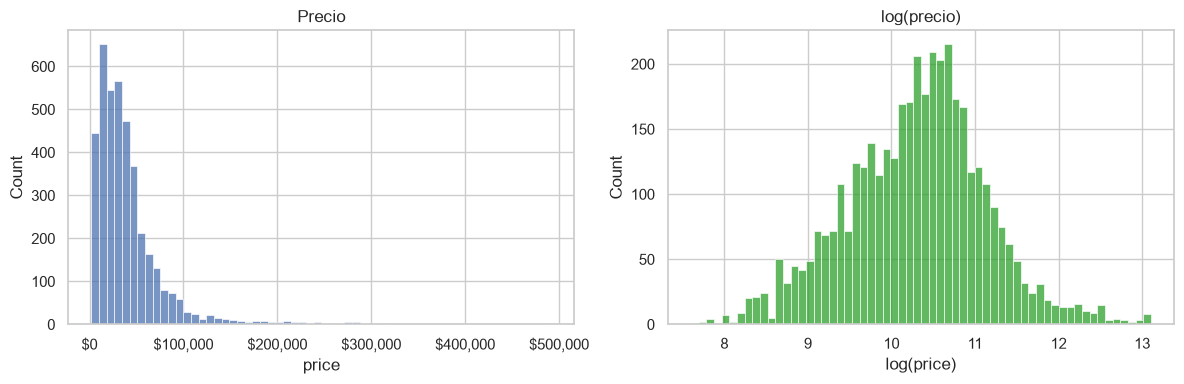

asimetría del precio: 4.36   de log(precio): -0.03


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(cars["price"], bins=60, ax=axes[0])
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set_title("Precio")
sns.histplot(np.log(cars["price"]), bins=60, ax=axes[1], color="tab:green")
axes[1].set_title("log(precio)")
axes[1].set_xlabel("log(price)")
fig.tight_layout()
plt.show()

print(f"asimetría del precio: {cars['price'].skew():.2f}   de log(precio): {np.log(cars['price']).skew():.2f}")

El precio tiene una asimetría de 4,36: la mayoría de los coches cuestan menos de 50.000 $,
pero hay una cola que llega a casi medio millón. Al aplicar el logaritmo, la distribución pasa a
ser casi simétrica (asimetría de -0,03).

Esto anticipa una decisión de modelado: es mejor predecir `log(precio)` que el precio directamente
(sección 7).

### 5.2 Variables numéricas frente al precio

Las gráficas siguientes enfrentan las tres variables numéricas más intuitivas con el precio, en
escala logarítmica.

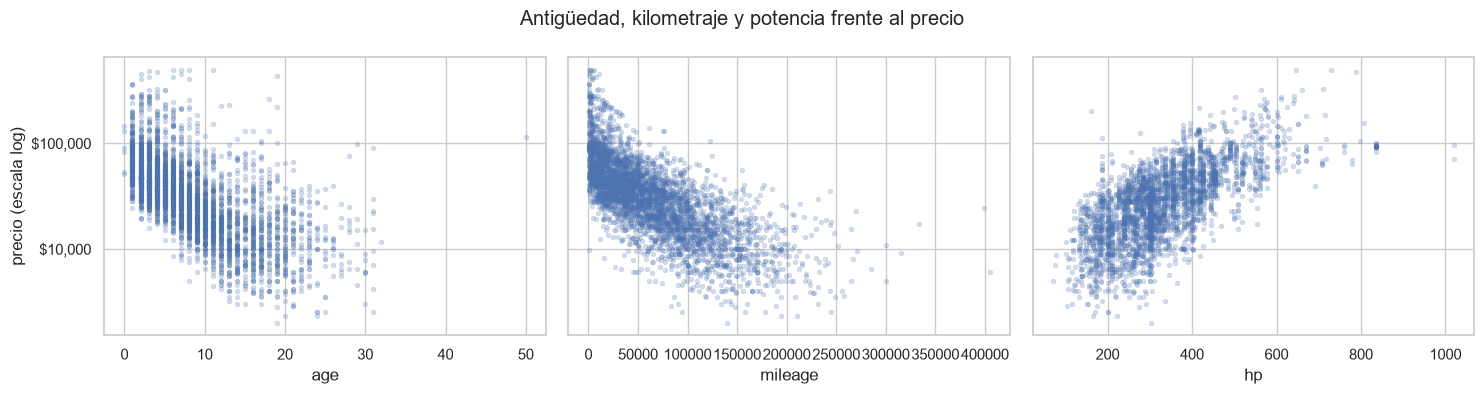

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ["age", "mileage", "hp"]):
    sns.scatterplot(data=cars, x=col, y="price", alpha=0.25, s=12, ax=ax, edgecolor=None)
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(dollars)
axes[0].set_ylabel("precio (escala log)")
fig.suptitle("Antigüedad, kilometraje y potencia frente al precio")
fig.tight_layout()
plt.show()

- **Antigüedad y kilometraje** reducen el precio de forma clara. En escala logarítmica la
  relación es aproximadamente recta, es decir, el coche **pierde un porcentaje de valor parecido
  cada año**. Esa es la definición de depreciación.
- **Potencia:** más potencia significa un coche más caro, de forma bastante consistente.
- Para una misma antigüedad, el precio puede variar en un factor de 10. La marca, la gama y el
  estado explican esa dispersión, y ninguna variable por sí sola basta.
- El coche de 50 años (de 1974) es un clásico con un precio alto: una no linealidad que un modelo
  lineal no puede capturar.

### 5.3 Correlaciones

El mapa de calor siguiente muestra la correlación de Spearman entre las variables numéricas y el
precio. Spearman usa rangos en lugar de valores, así que capta relaciones monótonas aunque no sean
lineales y no le afectan los precios extremos.

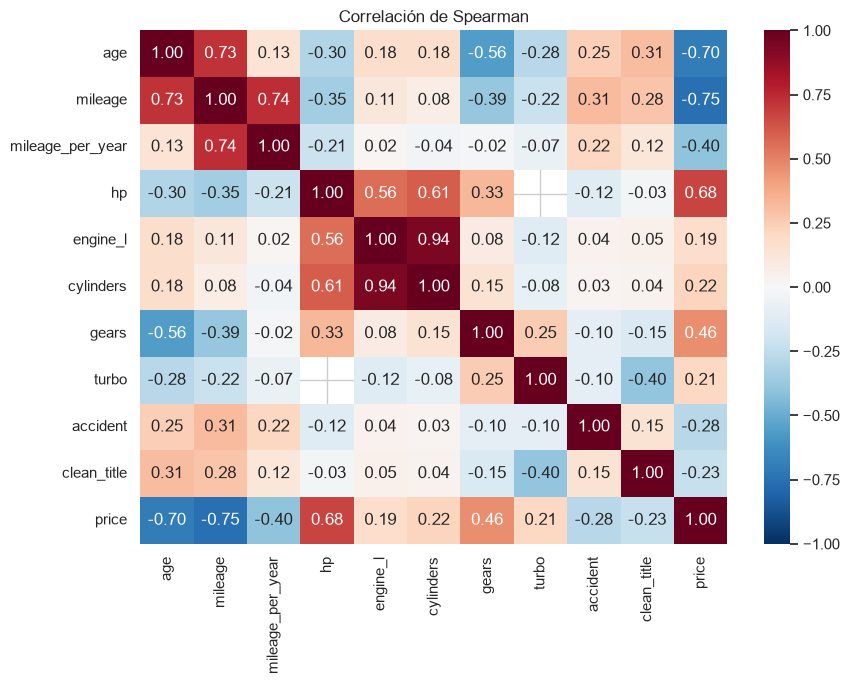

In [23]:
corr = cars[NUMERIC + BINARY + [TARGET]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Spearman")
fig.tight_layout()
plt.show()

- Las relaciones más fuertes con el precio son **kilometraje (-0,75), antigüedad (-0,70) y
  potencia (+0,68)**, como sugerían las gráficas.
- `gears` (+0,46) parece importante, pero también está muy correlacionada con la antigüedad (-0,56):
  las cajas de 8 a 10 marchas son recientes. En buena parte actúa como sustituto de la edad.
- **`engine_l` apenas se relaciona con el precio (0,19)**, aunque `hp` sí. Un motor grande no
  significa un coche caro: hay pick-ups americanas con V8 de 5 L más baratas que deportivos
  alemanes de 2 L turbo. Su efecto, si existe, depende de otras variables.
- `engine_l` y `cylinders` son casi redundantes (0,94), al igual que `age` y `mileage` (0,73). Esto
  afecta a la interpretación de un modelo lineal, pero no a su capacidad predictiva.
- La casilla `hp`-`turbo` sale vacía porque el indicador turbo solo aparece en el formato corto del
  motor, que nunca incluye la potencia. Es un artefacto de cómo el sitio web formatea el texto.

### 5.4 Variables categóricas frente al precio

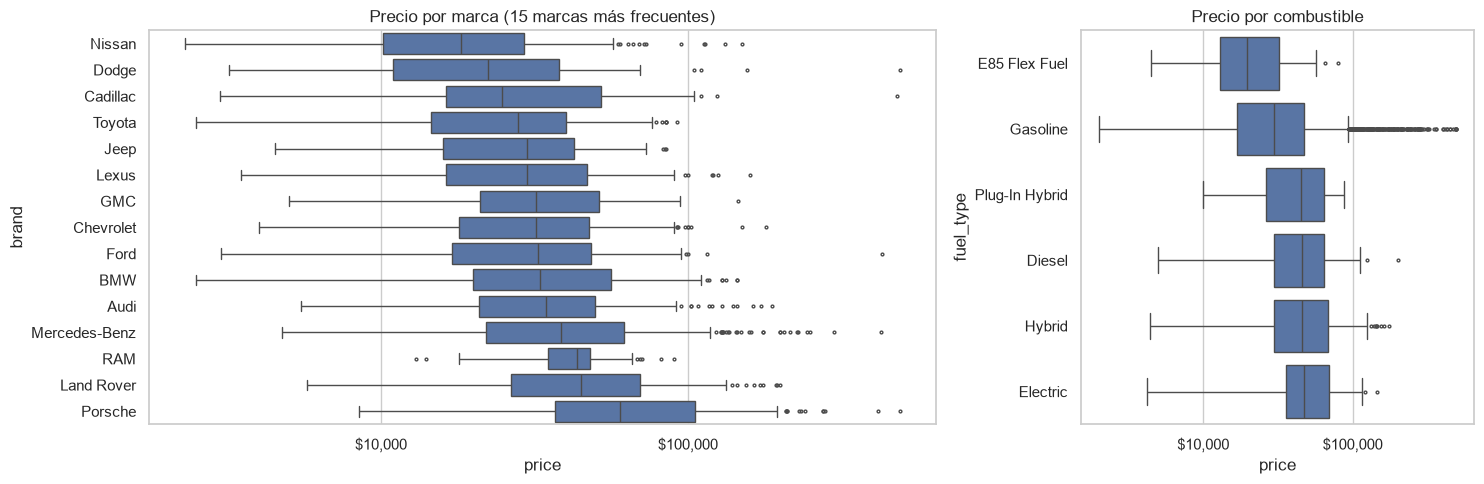

In [24]:
top_brands = cars["brand"].value_counts().head(15).index
brand_order = (
    cars[cars["brand"].isin(top_brands)].groupby("brand")["price"].median().sort_values().index
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
sns.boxplot(data=cars[cars["brand"].isin(top_brands)], x="price", y="brand",
            order=brand_order, ax=axes[0], fliersize=2)
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set_title("Precio por marca (15 marcas más frecuentes)")
fuel_order = cars.groupby("fuel_type")["price"].median().sort_values().index
sns.boxplot(data=cars, x="price", y="fuel_type", order=fuel_order, ax=axes[1], fliersize=2)
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(dollars)
axes[1].set_title("Precio por combustible")
fig.tight_layout()
plt.show()

In [25]:
pd.DataFrame({
    col: cars.groupby(col)["price"].median()
    for col in ["accident", "clean_title", "turbo"]
}).rename_axis("valor").map(lambda v: f"${v:,.0f}")

,accident,clean_title,turbo
valor,,,
0.0,"$35,500","$42,996","$29,900"
1.0,"$20,900","$28,998","$46,479"


- **La marca importa mucho.** La mediana va de unos 18.000 $ (Nissan) a más de 60.000 $
  (Porsche). Dentro de cada marca, el rango sigue siendo enorme.
- **Combustible.** Eléctricos, híbridos y diésel tienen medianas más altas que los de gasolina, en
  parte porque son coches más recientes. Los E85 Flex Fuel son los más baratos.
- **Accidentes.** Un coche con accidente reportado tiene una mediana de 20.900 $, frente a 35.500 $
  sin accidente. Parte de esa diferencia se debe a que suelen ser más viejos y con más kilometraje
  (correlación de 0,25 y 0,31).
- **`clean_title` engaña.** Los coches con título limpio *declarado* son más baratos (29.000 $ frente
  a 43.000 $). No es que un título limpio reste valor: los anuncios recientes de concesionario
  suelen omitir el campo (correlación con la antigüedad de +0,31). Correlación no es causalidad.

## 6. División entrenamiento / prueba

Igual que en la sesión 7, se separa el conjunto de prueba **antes de tocar ningún modelo** y no se
vuelve a mirar hasta el final. No se aparta un conjunto de validación: la validación cruzada lo
genera a partir de los datos de entrenamiento.

In [26]:
X = cars[FEATURES]
y = cars[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"filas de entrenamiento: {X_train.shape[0]}")
print(f"filas de prueba:        {X_test.shape[0]}")

filas de entrenamiento: 3200
filas de prueba:        801


## 7. El pipeline de preprocesamiento

En la sesión 7, el preprocesamiento se ajustó una sola vez sobre todo el conjunto de entrenamiento
y solo después se hizo la validación cruzada. Eso deja que cada fold de validación influya en su
propio preprocesamiento. Aquí, en cambio, **todo el preprocesamiento va dentro del pipeline**:
`cross_validate` lo reajusta en cada fold usando solo los datos de entrenamiento de ese fold.

Cada grupo de variables tiene su propio tratamiento:

| Grupo | Paso 1 | Paso 2 |
|---|---|---|
| numéricas | imputar con la **mediana** y añadir un **indicador de nulo** | **estandarizar** (media 0, desviación 1) |
| binarias | imputar con el valor **más frecuente** | — |
| categóricas | imputar con la categoría `"Unknown"` | **one-hot**, agrupando en `infrequent` las categorías con menos de 10 coches |

Algunas decisiones que conviene justificar:

- **Indicador de nulo** (`add_indicator=True`). Que falte la potencia puede ser información en sí:
  depende de cómo publicó el anuncio cada vendedor. El indicador deja que el modelo lo use.
- **`min_frequency=10`**. Una marca con 2 coches generaría una columna casi vacía que solo invita a
  sobreajustar. Agruparlas también resuelve el caso de una marca que aparece en prueba pero no en
  entrenamiento (`handle_unknown="infrequent_if_exist"`).
- **Estandarizar.** Es imprescindible para KNN y Ridge, y no afecta a los árboles. Así todos los
  candidatos comparten el mismo preprocesamiento.

> **En `scikit-learn`.** `make_preprocessor()` devuelve un objeto nuevo en cada llamada. Así cada
> modelo candidato tiene su propio preprocesador, sin estado compartido.

In [27]:
def make_preprocessor():
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    binary = SimpleImputer(strategy="most_frequent")
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                 sparse_output=False)),
    ])
    return ColumnTransformer(
        [("num", numeric, NUMERIC), ("bin", binary, BINARY), ("cat", categorical, CATEGORICAL)],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


preview = make_preprocessor().fit_transform(X_train)
print(f"{X_train.shape[1]} columnas originales -> {preview.shape[1]} columnas tras el preprocesamiento")
preview.head()

15 columnas originales -> 93 columnas tras el preprocesamiento


,age,mileage,mileage_per_year,hp,engine_l,cylinders,gears,missingindicator_hp,missingindicator_engine_l,missingindicator_cylinders,missingindicator_gears,turbo,accident,clean_title,brand_Acura,...,ext_color_White,ext_color_Yellow,ext_color_infrequent_sklearn,int_color_Beige,int_color_Black,int_color_Blue,int_color_Brown,int_color_Gray,int_color_Orange,int_color_Other,int_color_Red,int_color_Silver,int_color_Unknown,int_color_White,int_color_infrequent_sklearn
423,2.198119,1.073353,-0.367148,-0.976759,-0.343265,0.028669,0.057066,-0.495602,-0.116707,-0.258199,1.077359,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2992,-1.067576,-0.594534,1.039152,-0.149715,0.958909,1.031315,0.057066,2.017750,-0.116707,-0.258199,1.077359,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1517,-0.904292,-0.851502,-0.405598,-0.149715,0.047387,0.028669,0.799394,2.017750,-0.116707,-0.258199,-0.928196,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
506,-0.741007,-0.397809,0.465463,-0.149715,1.414670,1.031315,-0.685261,2.017750,-0.116707,-0.258199,-0.928196,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1163,-0.251152,-0.273476,-0.118223,-0.425396,0.047387,0.028669,0.799394,-0.495602,-0.116707,-0.258199,-0.928196,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Transformar el objetivo

La sección 5.1 mostró que el precio es muy asimétrico. Por eso los modelos se entrenan para
predecir `log(precio)` y la predicción se devuelve después a dólares con `exp`.
`TransformedTargetRegressor` hace las dos cosas automáticamente: las métricas y las predicciones
salen siempre en dólares.

Trabajar en escala logarítmica equivale a pedirle al modelo que se equivoque en *porcentaje* y no
en *dólares*. Un error de 5.000 $ en un coche de 10.000 $ es grave; en uno de 200.000 $ es
despreciable. La sección 11 comprueba si esta decisión mejora los resultados de verdad.

La función siguiente une preprocesador, modelo y transformación del objetivo en un único objeto.

In [28]:
def make_model(regressor, log_target=True):
    pipeline = Pipeline([("prepare", make_preprocessor()), ("model", regressor)])
    if not log_target:
        return pipeline
    return TransformedTargetRegressor(regressor=pipeline, func=np.log, inverse_func=np.exp)

## 8. El torneo: reglas y competidores

Para elegir el mejor modelo se organiza un torneo en dos rondas. Las reglas se fijan **antes** de
ver ningún resultado, para no ajustarlas después a favor de un favorito.

**Reglas**

1. **Mismas condiciones para todos.** Todos los modelos usan el mismo pipeline de preprocesamiento,
   la misma transformación del objetivo y **exactamente los mismos 5 folds** de validación cruzada.
2. **Métrica principal: MAE** (error absoluto medio, en dólares). Se eligió porque se interpreta
   directamente ("el modelo se equivoca de media X dólares") y porque, a diferencia del RMSE, no
   queda dominada por los pocos coches de lujo. RMSE, MAPE y R² se usan para confirmar.
3. **Un resultado es un rango.** Una ventaja menor que la variación entre folds no cuenta como
   victoria clara.
4. **Ronda 1 (fase de grupos):** los seis modelos compiten con hiperparámetros razonables por
   defecto. Los **dos mejores** pasan a la final.
5. **Ronda 2 (final):** se ajustan los hiperparámetros de los dos finalistas con `GridSearchCV`,
   para que ninguno pierda solo por tener una mala configuración de partida. Gana el de menor MAE de
   validación cruzada.
6. **El conjunto de prueba no participa en el torneo.** Se usa una sola vez, al final, para medir al
   campeón.

**Competidores**

Las cuatro familias de la sesión 7 (con Ridge en lugar de la regresión lineal simple) y dos
conjuntos de árboles:

- **Baseline (mediana).** Ignora las variables y predice siempre el precio mediano. Cualquier
  modelo útil debe superarlo.
- **Ridge.** Regresión lineal con regularización L2. Con decenas de columnas one-hot, la
  regularización evita coeficientes desmesurados.
- **KNN (k = 10).** Promedia el precio de los 10 coches más parecidos.
- **Árbol de decisión (profundidad 6).**
- **Random Forest.** Promedia cientos de árboles profundos, cada uno entrenado con una muestra
  distinta de filas y columnas. Al promediar se reduce la varianza de cada árbol por separado.
- **Gradient Boosting** (`HistGradientBoostingRegressor`). Construye árboles pequeños en secuencia,
  y cada uno corrige los errores de los anteriores. Suele ser el modelo más fuerte con datos
  tabulares.

In [29]:
candidates = {
    "Baseline (mediana)": DummyRegressor(strategy="median"),
    "Ridge": Ridge(alpha=1.0),
    "KNN (k=10)": KNeighborsRegressor(n_neighbors=10),
    "Árbol (profundidad 6)": DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

## 9. Ronda 1: fase de grupos

Cada competidor se evalúa con validación cruzada de 5 folds sobre el conjunto de entrenamiento.
Con `cross_validate` se obtienen varias métricas a la vez y, con `return_train_score=True`, también
el error de entrenamiento de cada fold. Ese error hace falta para el diagnóstico de sesgo y
varianza. También se registra el tiempo medio de entrenamiento.

Las métricas:

- **RMSE** (dólares). Penaliza mucho los errores grandes, así que está dominado por los coches
  caros.
- **MAE** (dólares). El error absoluto medio; es más robusto frente a los extremos.
- **MAPE** (%). El error porcentual medio, la métrica más intuitiva para precios: "el modelo se
  equivoca de media un X % del precio".
- **R²**. La proporción de la varianza del precio que explica el modelo.

> `KFold(shuffle=True)` baraja las filas antes de cortar los folds, y fijar `random_state` hace que
> **todos los modelos se evalúen en exactamente los mismos folds**. Así la comparación es justa.
> `n_jobs=-1` reparte los folds entre todos los núcleos del procesador.

In [30]:
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "mape": "neg_mean_absolute_percentage_error",
    "r2": "r2",
}

rows, fold_mae = [], {}
for name, regressor in candidates.items():
    cv = cross_validate(make_model(regressor), X_train, y_train, cv=CV, scoring=SCORING,
                        return_train_score=True, n_jobs=-1)
    fold_mae[name] = -cv["test_mae"]
    rows.append({
        "modelo": name,
        "MAE entrenamiento": -cv["train_mae"].mean(),
        "MAE CV": -cv["test_mae"].mean(),
        "MAE CV (desv.)": cv["test_mae"].std(),
        "RMSE entrenamiento": -cv["train_rmse"].mean(),
        "RMSE CV": -cv["test_rmse"].mean(),
        "MAPE CV (%)": -cv["test_mape"].mean() * 100,
        "R² CV": cv["test_r2"].mean(),
        "tiempo de ajuste (s)": cv["fit_time"].mean(),
    })

results = pd.DataFrame(rows).set_index("modelo").sort_values("MAE CV")
fold_mae = pd.DataFrame(fold_mae)[results.index]
results.round(2)

,MAE entrenamiento,MAE CV,MAE CV (desv.),RMSE entrenamiento,RMSE CV,MAPE CV (%),R² CV,tiempo de ajuste (s)
modelo,,,,,,,,
Gradient Boosting,5971.64,9141.31,349.81,14410.77,22101.79,22.02,0.76,0.76
Random Forest,4846.84,9872.70,444.04,14024.07,24302.13,24.07,0.71,3.68
Ridge,11042.12,11434.44,119.26,26461.50,27241.75,26.81,0.63,0.13
KNN (k=10),10926.04,12023.91,582.68,26875.72,28974.26,28.90,0.59,0.15
Árbol (profundidad 6),12015.17,14504.32,409.99,26384.05,32327.90,36.01,0.48,0.07
Baseline (mediana),24770.28,24773.98,1130.59,46725.47,46569.45,90.89,-0.06,0.13


Primeras conclusiones de la fase de grupos:

- **Todos los modelos superan con claridad a la baseline**, cuyo MAE es de 24.774 $ y su R² es
  -0,06, es decir, nada.
- **Gradient Boosting lidera** con un MAE de 9.141 $, un MAPE del 22 % y un R² de 0,76. Le sigue
  **Random Forest** (9.873 $). Por detrás quedan Ridge (11.434 $), KNN (12.024 $) y el árbol simple
  (14.504 $).
- El RMSE es unas 2,4 veces el MAE en todos los modelos. Es la señal de que hay algunos errores
  grandes, casi siempre en coches caros, que el RMSE penaliza al cuadrado. Por eso el MAE es la
  métrica principal.
- Random Forest es el más lento (3,4 s por ajuste), unas 4,5 veces más que Gradient Boosting
  (0,75 s).

### Clasificación por métrica

¿El orden depende de la métrica elegida? La tabla siguiente da el puesto de cada modelo en cada
métrica (1 = mejor) y el puesto medio.

In [31]:
ranking = pd.DataFrame({
    "MAE": results["MAE CV"].rank(),
    "RMSE": results["RMSE CV"].rank(),
    "MAPE": results["MAPE CV (%)"].rank(),
    "R²": results["R² CV"].rank(ascending=False),
}).astype(int)
ranking["puesto medio"] = ranking.mean(axis=1)
ranking.sort_values("puesto medio")

,MAE,RMSE,MAPE,R²,puesto medio
modelo,,,,,
Gradient Boosting,1,1,1,1,1.0
Random Forest,2,2,2,2,2.0
Ridge,3,3,3,3,3.0
KNN (k=10),4,4,4,4,4.0
Árbol (profundidad 6),5,5,5,5,5.0
Baseline (mediana),6,6,6,6,6.0


**El orden es idéntico en las cuatro métricas.** Gradient Boosting es primero en MAE, RMSE,
MAPE y R², y lo mismo ocurre con cada puesto hasta la baseline. El veredicto no depende de qué
métrica se elija, lo cual refuerza la elección del MAE como criterio principal.

### Un resultado de CV es un rango, no un punto

El gráfico siguiente muestra el MAE de cada uno de los 5 folds, en lugar de solo su media. Se
omite la baseline para que la escala deje ver las diferencias entre los modelos reales.

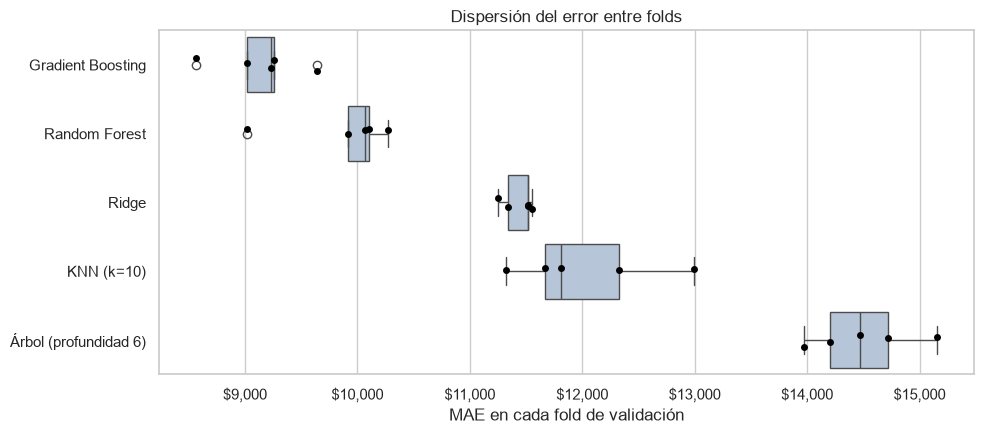

In [32]:
folds = fold_mae.drop(columns="Baseline (mediana)")

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=folds, orient="h", ax=ax, color="lightsteelblue")
sns.stripplot(data=folds, orient="h", ax=ax, color="black", size=5)
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel("MAE en cada fold de validación")
ax.set_title("Dispersión del error entre folds")
fig.tight_layout()
plt.show()

El gráfico muestra cada resultado como un rango. La caja de Gradient Boosting queda a la
izquierda de todas las demás. Pero **su rango se solapa con el de Random Forest**: el peor fold de
Gradient Boosting (unos 9.650 $) es peor que el mejor fold de Random Forest (unos 9.000 $). Mirando
solo los valores sueltos, no se podría afirmar con seguridad que uno es mejor que el otro.

Ridge, KNN y el árbol quedan claramente más a la derecha, a una distancia mayor que su propia
dispersión.

### Duelo fold a fold contra el líder

La desviación estándar de cada modelo por separado exagera la incertidumbre de la comparación.
Parte de la variación entre folds se debe a que unos folds son más difíciles que otros, y eso
afecta a **todos** los modelos a la vez.

Como todos se evaluaron en los mismos folds, se pueden comparar **por parejas**: en cada fold se
mira cuál de los dos acierta más y se calcula la diferencia de MAE. Si el líder gana en los 5 folds
y la diferencia media es grande frente a su desviación, la ventaja es consistente.

In [33]:
leader = results.index[0]
duel = pd.DataFrame({
    rival: {
        "folds ganados por el líder": int((fold_mae[leader] < fold_mae[rival]).sum()),
        "MAE extra del rival ($)": (fold_mae[rival] - fold_mae[leader]).mean(),
        "desv. de la diferencia ($)": (fold_mae[rival] - fold_mae[leader]).std(),
    }
    for rival in results.index[1:]
}).T
duel["folds ganados por el líder"] = duel["folds ganados por el líder"].astype(int).astype(str) + " / 5"
print(f"líder de la ronda 1: {leader}")
duel.round(0)

líder de la ronda 1: Gradient Boosting


,folds ganados por el líder,MAE extra del rival ($),desv. de la diferencia ($)
Random Forest,5 / 5,731.0,187.0
Ridge,5 / 5,2293.0,362.0
KNN (k=10),5 / 5,2883.0,431.0
Árbol (profundidad 6),5 / 5,5363.0,538.0
Baseline (mediana),5 / 5,15633.0,1125.0


La comparación por parejas resuelve la duda del gráfico anterior:

- **Gradient Boosting gana en los 5 folds a cada uno de los rivales.**
- Frente a Random Forest, la diferencia media es de 731 $ con una desviación de solo 187 $. La
  ventaja es unas 4 veces mayor que su propia variación. Las desviaciones individuales (350 $ y
  444 $) hacían pensar en un empate, porque incluían la dificultad de cada fold, que afecta a los dos
  modelos por igual.
- Frente a Ridge, KNN y el árbol, la ventaja es de entre 2.300 $ y 5.400 $: inequívoca.

**Pasan a la final: Gradient Boosting y Random Forest.**

## 10. Sesgo y varianza

Como en la sesión 7, la diferencia entre el error de validación y el de entrenamiento indica de
qué lado del equilibrio sesgo-varianza está cada modelo:

- **Mucho error en entrenamiento:** sesgo alto, el modelo es demasiado rígido (*underfitting*).
- **Una brecha grande entre validación y entrenamiento:** varianza alta, el modelo memoriza el
  conjunto de entrenamiento (*overfitting*).

In [34]:
results["brecha (CV - entrenamiento)"] = results["MAE CV"] - results["MAE entrenamiento"]
results[["MAE entrenamiento", "MAE CV", "brecha (CV - entrenamiento)"]].round(0)

,MAE entrenamiento,MAE CV,brecha (CV - entrenamiento)
modelo,,,
Gradient Boosting,5972.0,9141.0,3170.0
Random Forest,4847.0,9873.0,5026.0
Ridge,11042.0,11434.0,392.0
KNN (k=10),10926.0,12024.0,1098.0
Árbol (profundidad 6),12015.0,14504.0,2489.0
Baseline (mediana),24770.0,24774.0,4.0


La brecha muestra **por qué** pierde cada modelo:

- **Baseline:** brecha nula (4 $) y error enorme. Sesgo puro.
- **Ridge:** brecha muy pequeña (392 $) pero un error de entrenamiento alto (11.042 $). Es un modelo
  **con sesgo**: un modelo lineal no puede representar las interacciones de los datos. Por ejemplo,
  la depreciación no es igual en un Porsche que en un Nissan, y el efecto de la cilindrada depende
  de la potencia.
- **Random Forest:** el menor error de entrenamiento (4.847 $) y la **mayor brecha** (5.026 $). Sus
  árboles profundos memorizan parte del conjunto de entrenamiento: tiene **varianza**. El promedio
  de 300 árboles la reduce, pero no la elimina.
- **Gradient Boosting:** combina un error de entrenamiento bajo (5.972 $) con una brecha moderada
  (3.170 $). Es el que mejor equilibra sesgo y varianza, y por eso tiene el menor error de
  validación.

### El equilibrio en movimiento: la profundidad del árbol

`validation_curve` hace un barrido de un hiperparámetro y devuelve los errores de entrenamiento y
de validación cruzada para cada valor. La profundidad del árbol controla directamente el equilibrio
entre sesgo y varianza.

> El nombre del parámetro, `regressor__model__max_depth`, sigue la ruta dentro del objeto
> compuesto: `TransformedTargetRegressor` → `regressor` (el pipeline) → `model` (el árbol) →
> `max_depth`.

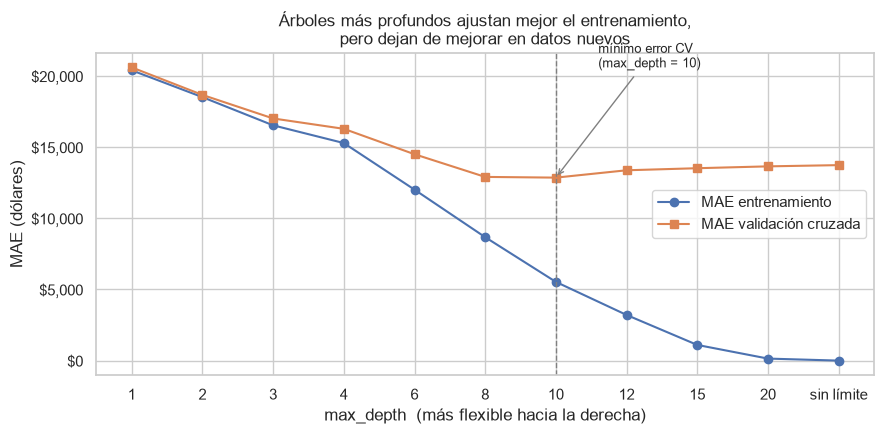

,max_depth,MAE entrenamiento,MAE CV
0,1,20402.0,20608.0
1,2,18517.0,18674.0
2,3,16536.0,17019.0
3,4,15290.0,16290.0
4,6,12015.0,14504.0
5,8,8674.0,12910.0
6,10,5532.0,12860.0
7,12,3208.0,13377.0
8,15,1101.0,13522.0
9,20,142.0,13652.0


In [35]:
depths = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, None]
train_scores, cv_scores = validation_curve(
    make_model(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    X_train, y_train,
    param_name="regressor__model__max_depth", param_range=depths,
    cv=CV, scoring="neg_mean_absolute_error", n_jobs=-1,
)
sweep = pd.DataFrame({
    "max_depth": ["sin límite" if d is None else str(d) for d in depths],
    "MAE entrenamiento": -train_scores.mean(axis=1),
    "MAE CV": -cv_scores.mean(axis=1),
})

positions = range(len(sweep))
best = sweep["MAE CV"].idxmin()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(positions, sweep["MAE entrenamiento"], marker="o", label="MAE entrenamiento")
ax.plot(positions, sweep["MAE CV"], marker="s", label="MAE validación cruzada")
ax.axvline(best, color="grey", linestyle="--", linewidth=1)
ax.annotate(f"mínimo error CV\n(max_depth = {sweep.loc[best, 'max_depth']})",
            xy=(best, sweep.loc[best, "MAE CV"]), xytext=(best + 0.6, sweep["MAE CV"].max()),
            arrowprops={"arrowstyle": "->", "color": "grey"}, fontsize=9)
ax.set_xticks(list(positions))
ax.set_xticklabels(sweep["max_depth"])
ax.set_xlabel("max_depth  (más flexible hacia la derecha)")
ax.set_ylabel("MAE (dólares)")
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Árboles más profundos ajustan mejor el entrenamiento,\npero dejan de mejorar en datos nuevos")
ax.legend(loc="center right")
fig.tight_layout()
plt.show()

sweep.round(0)

La curva reproduce lo visto en la sesión 7:

- **A la izquierda (profundidad 1-4)**, las dos curvas están altas y juntas. El árbol es demasiado
  simple (*underfitting*).
- **A la derecha**, el error de entrenamiento cae hasta **0** sin límite de profundidad (el árbol
  memoriza cada coche), mientras el de validación sube de 12.860 $ a 13.738 $ (*overfitting*).
- El mínimo está en **profundidad 8-10** (unos 12.900 $). El árbol de profundidad 6 de la ronda 1
  estaba por debajo de su punto óptimo.

Lo importante: **incluso en su mejor profundidad, el árbol individual (12.860 $) es peor que
Ridge (11.434 $)** y queda muy lejos de los conjuntos de árboles. Un solo árbol tiene que elegir
entre sesgo y varianza. Random Forest y Gradient Boosting reducen ese problema combinando muchos
árboles: el primero los **promedia** y el segundo los **suma** corrigiendo errores.

## 11. Una decisión de pipeline: transformar el objetivo

La lección central de la sección 9 de la plantilla es que **lo que se selecciona es un pipeline
completo, no un algoritmo**. Allí, escalar las variables cambió por completo el resultado de KNN.

Aquí la decisión equivalente es la transformación logarítmica del objetivo. La celda siguiente
valida los mismos modelos con y sin ella.

In [36]:
rows = []
for name in ["Ridge", "KNN (k=10)", "Gradient Boosting"]:
    for log_target in (False, True):
        cv = cross_validate(make_model(candidates[name], log_target=log_target), X_train, y_train,
                            cv=CV, scoring=SCORING, n_jobs=-1)
        rows.append({
            "modelo": name,
            "objetivo": "log(precio)" if log_target else "precio",
            "RMSE CV": -cv["test_rmse"].mean(),
            "MAE CV": -cv["test_mae"].mean(),
            "MAPE CV (%)": -cv["test_mape"].mean() * 100,
        })

pd.DataFrame(rows).set_index(["modelo", "objetivo"]).round(2)

RMSE CV    MAE CV  MAPE CV (%)
modelo            objetivo                                    
Ridge             precio       29836.99  16683.41        64.52
                  log(precio)  27241.75  11434.44        26.81
KNN (k=10)        precio       26888.17  12013.55        33.63
                  log(precio)  28974.26  12023.91        28.90
Gradient Boosting precio       22968.32  10230.81        26.68
                  log(precio)  22101.79   9141.31        22.02

**Transformar el objetivo es una de las decisiones que más influye en todo el proyecto:**

- **Ridge** es el que más mejora: el MAE baja de 16.683 $ a 11.434 $ y el MAPE del 64,5 % al 26,8 %.
  Un modelo lineal sobre `log(precio)` modela efectos **multiplicativos** ("cada año resta un X % del
  valor"). Eso coincide con la depreciación observada en el EDA. Sobre el precio en dólares, en
  cambio, Ridge supone que cada año resta los mismos dólares a un Porsche que a un Nissan.
- **Gradient Boosting** también mejora: de 10.231 $ a 9.141 $ de MAE.
- **KNN** queda igual en MAE, mejora en MAPE y empeora en RMSE. Al promediar vecinos en escala log
  calcula una media geométrica, que tiende a quedarse corta con los coches caros.

Con la métrica principal, la transformación mejora a 2 de los 3 modelos y empata con el tercero. Se
mantiene para todos, y se confirma la lección de la plantilla: **se selecciona un pipeline completo,
no un algoritmo**.

## 12. Ronda 2: la final

Pasan a la final los dos primeros de la fase de grupos. Hasta ahora competían con hiperparámetros
por defecto, y la sesión 7 ya advertía que un modelo puede perder solo por estar mal configurado (el
árbol de profundidad 4 estaba pasado de su punto óptimo). Por eso, en la final, **cada finalista
compite con su mejor versión**.

`GridSearchCV` prueba todas las combinaciones de una rejilla de hiperparámetros, evalúa cada una con
**los mismos 5 folds** y se queda con la de menor MAE (`refit="mae"`). Después reentrena esa
configuración con todo el conjunto de entrenamiento.

Las rejillas son pequeñas a propósito (16 y 9 combinaciones), centradas en los hiperparámetros que
más influyen en cada modelo:

| Finalista | Hiperparámetros ajustados |
|---|---|
| Gradient Boosting | `learning_rate` (tamaño de cada corrección), `max_iter` (número de árboles), `max_leaf_nodes` (complejidad de cada árbol), `l2_regularization` |
| Random Forest | `max_features` (fracción de variables por división), `min_samples_leaf` (tamaño mínimo de una hoja) |

In [37]:
GRIDS = {
    "Gradient Boosting": (
        HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "regressor__model__learning_rate": [0.03, 0.1],
            "regressor__model__max_iter": [300, 800],
            "regressor__model__max_leaf_nodes": [15, 31],
            "regressor__model__l2_regularization": [0.0, 1.0],
        },
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        {
            "regressor__model__max_features": [0.33, 0.66, 1.0],
            "regressor__model__min_samples_leaf": [1, 2, 4],
        },
    ),
}
finalists = list(results.index[:2])
print(f"finalistas: {finalists}")

searches, rows = {}, []
for name in finalists:
    regressor, grid = GRIDS[name]
    search = GridSearchCV(make_model(regressor), grid, cv=CV, scoring=SCORING, refit="mae",
                          n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    cv_res, best_i = search.cv_results_, search.best_index_
    rows.append({
        "modelo": name,
        "MAE CV (ronda 1)": results.loc[name, "MAE CV"],
        "MAE CV (ajustado)": -cv_res["mean_test_mae"][best_i],
        "MAE CV (desv.)": cv_res["std_test_mae"][best_i],
        "RMSE CV": -cv_res["mean_test_rmse"][best_i],
        "MAPE CV (%)": -cv_res["mean_test_mape"][best_i] * 100,
        "R² CV": cv_res["mean_test_r2"][best_i],
    })
    best_params = {k.split("__")[-1]: v for k, v in search.best_params_.items()}
    print(f"mejores hiperparámetros de {name}: {best_params}")

final_round = pd.DataFrame(rows).set_index("modelo").sort_values("MAE CV (ajustado)")
champion_name = final_round.index[0]
final_round.round(2)

finalistas: ['Gradient Boosting', 'Random Forest']


mejores hiperparámetros de Gradient Boosting: {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_iter': 800, 'max_leaf_nodes': 31}


mejores hiperparámetros de Random Forest: {'max_features': 1.0, 'min_samples_leaf': 1}


,MAE CV (ronda 1),MAE CV (ajustado),MAE CV (desv.),RMSE CV,MAPE CV (%),R² CV
modelo,,,,,,
Gradient Boosting,9141.31,8831.67,377.06,21776.27,21.48,0.77
Random Forest,9872.70,9614.81,483.43,23631.50,23.70,0.72


El ajuste mejora a ambos finalistas, pero **no cambia el resultado**:

- **Gradient Boosting:** de 9.141 $ a **8.832 $** (-3,4 %). Su mejor configuración es
  `learning_rate=0.03`, `max_iter=800`, `max_leaf_nodes=31` y `l2_regularization=0`: muchos árboles,
  cada uno aportando una corrección pequeña. Es la receta clásica del boosting.
- **Random Forest:** de 9.873 $ a **9.615 $** (-2,6 %), con `max_features=1.0` y
  `min_samples_leaf=1`.

Las mejoras (unos 300 $) son del mismo orden que la variación entre folds (unos 400 $). El ajuste
afina los modelos, pero lo que decide es la familia del modelo. De hecho, **Gradient Boosting sin
ajustar (9.141 $) ya era mejor que Random Forest ajustado (9.615 $)**.

### El duelo de la final, fold a fold

Igual que en la ronda 1, se comparan los dos finalistas ajustados en cada uno de los 5 folds.

In [38]:
def best_fold_mae(search):
    return np.array([-search.cv_results_[f"split{k}_test_mae"][search.best_index_]
                     for k in range(CV.get_n_splits())])


final_folds = pd.DataFrame({name: best_fold_mae(searches[name]) for name in final_round.index},
                           index=pd.RangeIndex(1, 6, name="fold"))
runner_up = final_round.index[1]
final_folds["diferencia"] = final_folds[runner_up] - final_folds[champion_name]
print(f"campeón: {champion_name}")
print(f"gana {int((final_folds['diferencia'] > 0).sum())} de 5 folds; "
      f"diferencia media {final_folds['diferencia'].mean():,.0f} $ "
      f"(desv. {final_folds['diferencia'].std():,.0f} $)")
final_folds.round(0)

campeón: Gradient Boosting
gana 5 de 5 folds; diferencia media 783 $ (desv. 277 $)


,Gradient Boosting,Random Forest,diferencia
fold,,,
1,9004.0,9919.0,915.0
2,8797.0,9842.0,1045.0
3,8578.0,9533.0,956.0
4,9442.0,10067.0,626.0
5,8338.0,8713.0,375.0


**Gradient Boosting gana la final en los 5 folds**, con una ventaja media de 783 $
(desviación de 277 $) sobre Random Forest ajustado. Ninguno de los dos perdió por estar mal
configurado: ambos compitieron con su mejor versión.

🏆 **Campeón del torneo: Gradient Boosting.**

## 13. ¿Por qué gana Gradient Boosting?

La pregunta no es solo *quién* gana, sino *por qué*, y si la victoria es lo bastante sólida para
confiar en ella. Los argumentos, en orden de importancia:

**1. Gana en todas las métricas y en todos los folds.** Es primero en MAE, RMSE, MAPE y R², tanto en
la fase de grupos como en la final. En las comparaciones por parejas supera a **cada rival en los 5
folds**. Frente al rival más cercano, Random Forest, la ventaja (731-783 $) es entre 3 y 4 veces su
propia variación. No es una victoria por un golpe de suerte en un fold.

**2. Es el que mejor equilibra sesgo y varianza** (sección 10):

| Modelo | Problema principal | Evidencia |
|---|---|---|
| Ridge | **sesgo**: demasiado rígido | error de entrenamiento alto (11.042 $), brecha mínima |
| Árbol | **varianza** | incluso con la profundidad óptima (12.860 $) es peor que Ridge |
| KNN | sesgo y escala | todas las variables pesan igual en la distancia |
| Random Forest | **varianza** residual | el menor error de entrenamiento, pero la mayor brecha (5.026 $) |
| **Gradient Boosting** | equilibrado | error de entrenamiento bajo **y** brecha moderada |

**3. Su mecanismo encaja con la estructura de los datos.** El EDA mostró que el precio depende de
relaciones **no lineales** (la depreciación es exponencial y los clásicos se revalorizan) y de
**interacciones** (una marca premium se deprecia distinto; la cilindrada solo importa en combinación
con la potencia). Gradient Boosting construye cientos de árboles pequeños en secuencia, y cada uno
se centra en los coches que los anteriores tasaron peor. Así captura esos patrones sin memorizar el
ruido, porque cada árbol aporta solo una pequeña corrección (`learning_rate=0.03`).

**4. No gana solo por estar mejor configurado.** Random Forest también se ajustó en la final, y aun
así Gradient Boosting *sin ajustar* ya lo superaba. La ventaja viene de la familia del modelo, no de
la configuración.

**5. Es práctico.** Se entrena en menos de 1 segundo, unas 4,5 veces más rápido que Random Forest, y
el modelo guardado es más ligero.

**Lo que cuesta elegirlo.** Gradient Boosting es menos interpretable que Ridge: no tiene
coeficientes que se puedan leer directamente. Si la interpretabilidad fuera un requisito, Ridge
sería la alternativa razonable, a cambio de unos 2.600 $ más de error medio por coche. Para tasar
precios, la precisión pesa más, y la sección 15 recupera parte de la interpretabilidad con la
importancia por permutación.

**La confirmación definitiva** llega en la sección siguiente: si la elección es correcta, el
campeón debe rendir en el conjunto de prueba lo que predijo la validación cruzada.

## 14. Evaluación final en el conjunto de prueba

El torneo ha terminado. Solo ahora se usa el conjunto de prueba, **una única vez**, para medir al
campeón con datos que no han intervenido en ninguna decisión.

`GridSearchCV` ya reentrenó la mejor configuración con todo el conjunto de entrenamiento (`refit`),
así que `best_estimator_` es el modelo final.

In [39]:
search = searches[champion_name]
final_model = search.best_estimator_
y_pred = final_model.predict(X_test)

test_metrics = pd.Series({
    "RMSE ($)": root_mean_squared_error(y_test, y_pred),
    "MAE ($)": mean_absolute_error(y_test, y_pred),
    "MAPE (%)": mean_absolute_percentage_error(y_test, y_pred) * 100,
    "R²": r2_score(y_test, y_pred),
}, name="prueba")
cv_metrics = pd.Series({
    "RMSE ($)": -search.cv_results_["mean_test_rmse"][search.best_index_],
    "MAE ($)": -search.cv_results_["mean_test_mae"][search.best_index_],
    "MAPE (%)": -search.cv_results_["mean_test_mape"][search.best_index_] * 100,
    "R²": search.cv_results_["mean_test_r2"][search.best_index_],
}, name="validación cruzada")
pd.concat([cv_metrics, test_metrics], axis=1).round(3)

,validación cruzada,prueba
RMSE ($),21776.275,22276.200
MAE ($),8831.665,8581.701
MAPE (%),21.484,19.066
R²,0.766,0.779


**El campeón cumple lo que prometió la validación cruzada:**

- **MAE de 8.582 $** en prueba, frente a los 8.832 $ estimados por validación cruzada.
- **MAPE del 19,1 %**: de media, el modelo se equivoca en una quinta parte del precio.
- **R² de 0,78**: explica el 78 % de la variabilidad del precio con datos que nunca había visto.

Todas las métricas de prueba están dentro de la variación esperada (la desviación del MAE entre
folds era de unos 380 $). Que el resultado sea incluso algo mejor en prueba es azar del muestreo,
no una mejora real. Lo importante es que **no hay caída**: el proceso de selección no ha sobreajustado
la validación cruzada.

### Comprobación didáctica: ¿acertó el torneo?

Como en la sección 10 de la plantilla, y **solo con fines didácticos**, la celda siguiente mide
también en prueba a todos los demás competidores. En un trabajo real esto no se haría: en cuanto se
comparan varios modelos en el conjunto de prueba, ese conjunto pasa a usarse para elegir y deja de
ser una estimación limpia. Aquí sirve para comprobar si el veredicto de la validación cruzada se
sostiene con datos nuevos.

In [40]:
check = {name: make_model(regressor).fit(X_train, y_train) for name, regressor in candidates.items()}
check |= {f"{name} (ajustado)": searches[name].best_estimator_ for name in final_round.index}

pd.DataFrame({
    name: {
        "MAE CV": (results.loc[name, "MAE CV"] if name in results.index
                   else final_round.loc[name.removesuffix(" (ajustado)"), "MAE CV (ajustado)"]),
        "MAE prueba": mean_absolute_error(y_test, model.predict(X_test)),
    }
    for name, model in check.items()
}).T.sort_values("MAE CV").round(0)

,MAE CV,MAE prueba
Gradient Boosting (ajustado),8832.0,8582.0
Gradient Boosting,9141.0,8818.0
Random Forest (ajustado),9615.0,9307.0
Random Forest,9873.0,9578.0
Ridge,11434.0,11174.0
KNN (k=10),12024.0,11613.0
Árbol (profundidad 6),14504.0,14435.0
Baseline (mediana),24774.0,24455.0


**El orden en el conjunto de prueba coincide exactamente con el de la validación cruzada**,
en los 8 modelos: Gradient Boosting ajustado > Gradient Boosting > Random Forest ajustado > Random
Forest > Ridge > KNN > árbol > baseline. El ajuste de hiperparámetros también se confirma: las dos
versiones ajustadas son mejores en prueba que sus versiones por defecto.

El torneo eligió correctamente y lo hizo sin mirar el conjunto de prueba.

### Predicciones frente a valores reales

Si el modelo fuera perfecto, todos los puntos caerían sobre la diagonal. El panel de la derecha
muestra el error porcentual según el rango de precio real.

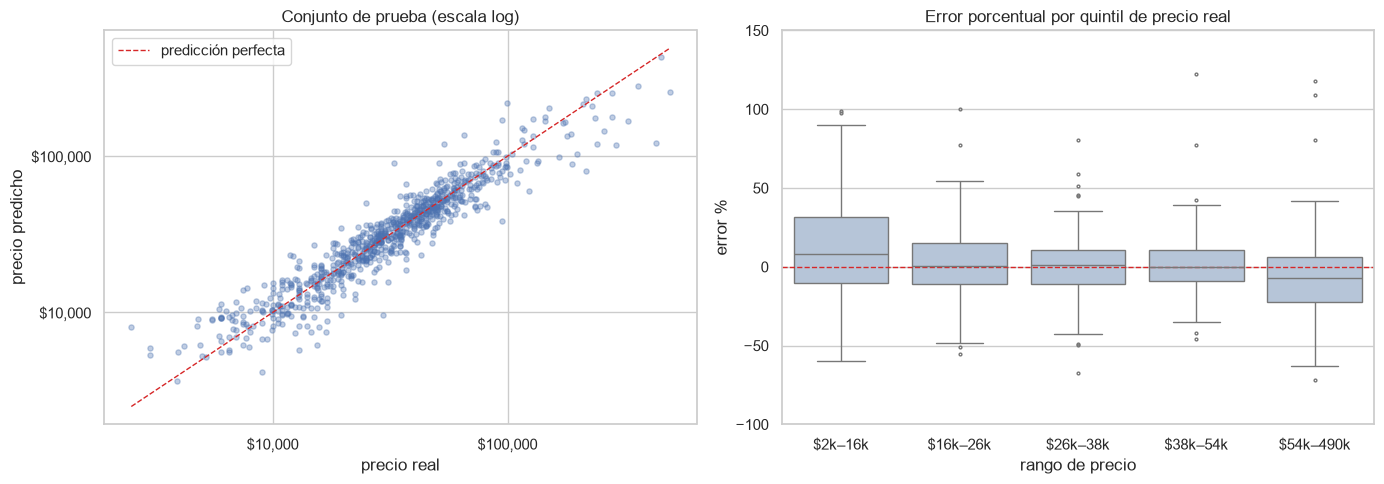

,mediana,error_abs_medio
rango de precio,,
$2k–16k,7.9,27.9
$16k–26k,0.5,17.5
$26k–38k,1.3,16.2
$38k–54k,-0.2,13.8
$54k–490k,-7.0,19.9


In [41]:
errors = pd.DataFrame({"real": y_test, "predicho": y_pred})
errors["error %"] = (errors["predicho"] - errors["real"]) / errors["real"] * 100
errors["rango de precio"] = pd.qcut(errors["real"], 5).cat.rename_categories(
    lambda iv: f"${iv.left / 1000:,.0f}k–{iv.right / 1000:,.0f}k"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.scatter(errors["real"], errors["predicho"], alpha=0.35, s=14)
lims = [errors[["real", "predicho"]].min().min(), errors[["real", "predicho"]].max().max()]
ax.plot(lims, lims, color="tab:red", linestyle="--", linewidth=1, label="predicción perfecta")
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(dollars)
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("precio real")
ax.set_ylabel("precio predicho")
ax.set_title("Conjunto de prueba (escala log)")
ax.legend()

sns.boxplot(data=errors, x="rango de precio", y="error %", ax=axes[1], color="lightsteelblue",
            fliersize=2)
axes[1].axhline(0, color="tab:red", linestyle="--", linewidth=1)
axes[1].set_ylim(-100, 150)
axes[1].set_title("Error porcentual por quintil de precio real")
fig.tight_layout()
plt.show()

errors.groupby("rango de precio", observed=True)["error %"].agg(
    mediana="median", error_abs_medio=lambda e: e.abs().mean()
).round(1)

- En escala logarítmica, los puntos siguen bien la diagonal en todo el rango, desde 3.000 $
  hasta casi 500.000 $.
- **El error relativo es mayor en los extremos.** En los coches más baratos (menos de 16.000 $), el
  error absoluto medio es del 28 % y el modelo tiende a **sobrestimar** (mediana del +7,9 %). En los
  más caros (más de 54.000 $) tiende a **subestimar** (mediana del -7 %). Es la *regresión a la
  media* típica: con menos ejemplos en los extremos, el modelo empuja sus predicciones hacia el
  centro.
- En el rango central (16.000-54.000 $), donde está la mayoría de los coches, el error absoluto
  medio baja al 14-18 %.

### Los peores errores

Revisar las predicciones con más error ayuda a entender los límites del modelo.

In [42]:
worst = errors.assign(abs_err=errors["error %"].abs()).nlargest(8, "abs_err").index
X_test.loc[worst, ["brand", "age", "mileage", "hp", "fuel_type", "accident"]].join(
    errors.loc[worst, ["real", "predicho", "error %"]].round(0)
)

,brand,age,mileage,hp,fuel_type,accident,real,predicho,error %
1288,BMW,24,177700.0,170.0,Gasoline,0.0,2500.0,8118.0,225.0
3988,Aston Martin,21,14900.0,420.0,Gasoline,NaN,32850.0,91014.0,177.0
222,Dodge,2,1240.0,NaN,Gasoline,0.0,53900.0,119861.0,122.0
205,Lexus,2,2071.0,NaN,Gasoline,0.0,99950.0,218014.0,118.0
2623,Dodge,9,1800.0,707.0,Gasoline,0.0,64990.0,135998.0,109.0
32,BMW,4,35035.0,NaN,Hybrid,0.0,24998.0,50068.0,100.0
2251,BMW,23,53814.0,326.0,Gasoline,NaN,11800.0,23477.0,99.0
3013,Ford,14,232000.0,292.0,Gasoline,0.0,3000.0,5937.0,98.0


Los peores errores siguen unos patrones claros:

- **Falta la potencia** (`hp = NaN`) en varios casos. En coches seminuevos con muy pocas millas, el
  modelo imputa la mediana y se equivoca mucho de gama, como con el Lexus o el Dodge de 2 años
  tasados en el doble de su precio.
- **Coches viejos y baratos** (BMW de 24 años a 2.500 $, Ford de 232.000 millas a 3.000 $). En
  términos absolutos el error es pequeño (unos 3.000-5.000 $), pero en porcentaje es enorme.
- **Ejemplares atípicos de marcas premium**, como un Aston Martin de 21 años que se ha depreciado
  mucho más de lo que la marca sugiere.

La causa de fondo es común: **el modelo no conoce el modelo concreto ni el acabado** (`model` se
descartó). Dentro de una marca, un Dodge Viper y un Dodge Journey son coches muy distintos.

## 15. ¿Qué ha aprendido el modelo?

La **importancia por permutación** desordena una variable cada vez y mide cuánto empeora el modelo.
Si la variable importa, desordenarla destruye información y el error sube.

Se calcula sobre las **variables originales**, antes del one-hot: el pipeline completo recibe la
columna desordenada. Así `brand` aparece como una sola variable, no como 30 columnas sueltas. Se
usa el conjunto de prueba porque esto es interpretación del modelo final, no selección.

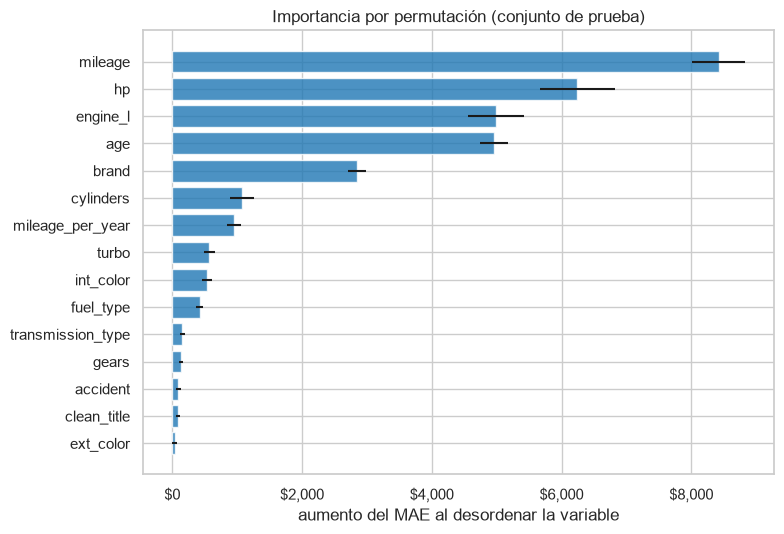

In [43]:
importance = permutation_importance(
    final_model, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)
importance = pd.DataFrame(
    {"aumento del MAE ($)": importance.importances_mean, "desv.": importance.importances_std},
    index=X_test.columns,
).sort_values("aumento del MAE ($)")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(importance.index, importance["aumento del MAE ($)"], xerr=importance["desv."],
        color="tab:blue", alpha=0.8)
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel("aumento del MAE al desordenar la variable")
ax.set_title("Importancia por permutación (conjunto de prueba)")
fig.tight_layout()
plt.show()

- **Kilometraje, potencia, cilindrada y antigüedad** son las cuatro variables más importantes:
  desordenar cualquiera de ellas sube el error entre 5.000 y 8.400 $. Después viene la **marca**
  (unos 2.800 $).
- **La cilindrada (`engine_l`) es la tercera más importante, aunque su correlación con el precio era
  solo de 0,19.** Es la mejor prueba de por qué gana un modelo no lineal: la cilindrada no informa
  por sí sola, sino **combinada** con la potencia y la marca. Gradient Boosting aprovecha esa
  interacción, mientras que la correlación (y un modelo lineal) no la ven.
- `accident` y `clean_title` apenas aportan, pese a las diferencias de mediana de la sección 5.4. Su
  información ya está contenida en la antigüedad y el kilometraje. El color exterior no aporta
  nada.

### Guardar el modelo

El pipeline completo (limpieza de nulos, codificación, escalado, modelo y transformación del
objetivo) se guarda en un solo archivo. Para usarlo con un coche nuevo basta con
`joblib.load(...)` y `.predict(df)`, siempre que `df` tenga las mismas columnas limpias de
`FEATURES`.

In [44]:
MODEL_PATH = Path("models/modelo_precio_coches.joblib")
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(final_model, MODEL_PATH)

example = X_test.iloc[[0]]
print(example.T.to_string())
print(f"\nprecio real:     ${y_test.iloc[0]:,.0f}")
print(f"precio predicho: ${final_model.predict(example)[0]:,.0f}")

                         555
age                        0
mileage               3880.0
mileage_per_year      3880.0
hp                       NaN
engine_l                 2.5
cylinders                NaN
gears                    8.0
turbo                      0
accident                 0.0
clean_title                1
brand                  Mazda
fuel_type           Gasoline
transmission_type  Automatic
ext_color               Gray
int_color              Black

precio real:     $52,991
precio predicho: $39,450


## 16. Conclusiones

**Sobre los datos**

- Un dataset real de Kaggle necesitó una limpieza considerable antes de poder modelarse: precios y
  kilometraje como texto, nulos disfrazados de guiones, eléctricos sin combustible, marcas partidas,
  motores y transmisiones en texto libre y un precio erróneo de casi 3 millones.
- El EDA guio decisiones concretas: modelar `log(precio)`, recuperar el combustible de los
  eléctricos, agrupar categorías raras y limitar el alcance a coches de hasta 500.000 $.

**Sobre el torneo**

- Seis modelos compitieron en igualdad de condiciones: mismo pipeline, mismos folds y reglas fijadas
  de antemano.
- **Gradient Boosting es el campeón.** Es primero en las cuatro métricas y en todos los folds, gana
  la final contra Random Forest ajustado y su ventaja es varias veces mayor que la variación entre
  folds.
- En prueba: **MAE de 8.582 $, MAPE del 19 % y R² de 0,78**, en línea con la validación cruzada. El
  orden de los 8 modelos en prueba coincide exactamente con el de la validación cruzada.

**Lecciones de la plantilla que se confirman**

- Se selecciona un **pipeline**, no un algoritmo. La transformación logarítmica redujo el MAE de
  Ridge en un 31 %.
- Un resultado de validación cruzada es un **rango**. Los rangos de Gradient Boosting y Random
  Forest se solapaban, y la comparación fold a fold fue la que demostró que la ventaja era consistente.
- La brecha entre entrenamiento y validación explica **por qué** pierde cada modelo: Ridge por sesgo,
  el árbol y Random Forest por varianza.

**Limitaciones**

- El modelo no usa `model` ni el acabado, que es la mayor fuente de error que queda.
- Solo es válido para coches de hasta 500.000 $ del mercado estadounidense (cars.com, 2023-2024).
- El error relativo en coches de menos de 16.000 $ (28 %) es alto para un uso real en ese segmento.

**Posibles mejoras**

- Codificar `model` con *target encoding* dentro del pipeline, para aprovechar la información de la
  gama sin crear 1.900 columnas.
- Probar XGBoost o LightGBM con búsqueda bayesiana de hiperparámetros (Optuna, sesión 6).
- Predecir intervalos además de un valor puntual (regresión cuantílica), para decir "entre 25.000 $
  y 32.000 $" en lugar de un único número.